# 4. Modeling: Pelatihan, Komparasi, dan Optimasi Multi-Model Pembelajaran Mesin

Tahap **Modeling** dalam kerangka kerja **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*) berfokus pada pemilihan, perancangan arsitektur, pelatihan, dan komparasi performa algoritma pembelajaran mesin untuk mengklasifikasikan 5 kategori tutupan lahan di Jawa Timur berdasarkan **29 Fitur Spektral Fisik Terpadu**.

Pada pengolahan data tabular spektral satelit Copernicus Sentinel-2 Level-2A, algoritma keluarga pohon keputusan (*decision tree ensembles*) memiliki keunggulan inheren:
* **Non-linearitas spektral**: Mampu memetakan batas keputusan rumit antara pantulan gelombang elektromagnetik dan biofisik tutupan lahan.
* **Resisten terhadap multikolinearitas**: Tangguh terhadap korelasi tinggi antar-indeks vegetasi dan band spektral berdekatan.
* **Invarian terhadap skala**: Tahan terhadap disparitas rentang nilai indeks tanpa memerlukan normalisasi distribusi normal yang ketat.

---

### Alur Eksperimen Pemodelan Bertingkat:
1. **Model Baseline**: Menguji 4 algoritma dasar (*Random Forest*, *LightGBM*, *XGBoost*, *ExtraTrees*) dengan parameter bawaan (*default*) sebagai acuan pembanding awal (*benchmark*).
2. **Model Teroptimasi (*Tuned Models*)**: Melakukan penyetelan hyperparameter pada keempat algoritma untuk meminimalisasi variansi dan meningkatkan kestabilan generalisasi.
3. **Model Ansambel (*Ensemble Models*)**:
   * **Equal-Weighted Soft Voting Ensemble**: Menggabungkan probabilitas posterior keempat estimator dengan bobot seragam.
   * **Weighted Soft Voting Ensemble (`model_terbaik.pkl`)**: Meta-ansambel dengan pembobotan teroptimasi: **LGBM (1.2), XGB (1.2), RF (1.0), ET (1.0)**.
4. **Validasi Silang (*Stratified 5-Fold Cross-Validation*)**: Memastikan seluruh perbandingan model diuji secara obyektif dan berulang tanpa menyentuh data uji independen.

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings('ignore')

# Konfigurasi Tampilan Visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print('[OK] Seluruh library Machine Learning dan utilitas komparasi berhasil dimuat.')

[OK] Seluruh library Machine Learning dan utilitas komparasi berhasil dimuat.


## 4.1 Pemuatan Data Training dan Konfigurasi Validasi Silang (Stratified 5-Fold CV)

Dataset latih dimuat dari direktori `../3-data_preparation/prepared_data/train_data.csv` (200 sampel poligon seimbang, masing-masing 40 sampel per kelas).

Untuk menguji performa model secara obyektif dan konsisten selama tahap pelatihan, diterapkan protokol **Stratified 5-Fold Cross-Validation**:
* Data latih dibagi menjadi 5 bagian (*folds*) berukuran setara (40 sampel per fold, 8 per kelas seimbang).
* Setiap model dilatih pada 4 fold (160 sampel) dan diuji pada 1 fold tersisa (40 sampel).
* Proses diulang sebanyak 5 kali secara berputar (*iteratif*), dan nilai rata-rata akurasi (*CV Mean Accuracy*) serta simpangan bakunya (*Standard Deviation*) dicatat sebagai indikator kinerja dan stabilitas model.

In [2]:
data_dir = os.path.join('..', '3-data_preparation', 'prepared_data')
train_df = pd.read_csv(os.path.join(data_dir, 'train_data.csv'))

# Ekstraksi 29 kolom fitur spektral
exclude_cols = ['sample_id', 'class_name', 'class_id', 'centroid_lon', 'centroid_lat', 'pixel_count', 'label']
feature_cols = [c for c in train_df.columns if c not in exclude_cols]

X_train = train_df[feature_cols].values
y_train = train_df['label'].values

# Konfigurasi Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f'Dimensi X_train : {X_train.shape} (200 sampel, {len(feature_cols)} fitur spektral fisik)')
print(f'Dimensi y_train : {y_train.shape}')
print('Distribusi Sampel per Kelas pada Data Latih:', pd.Series(y_train).value_counts().sort_index().to_dict())

Dimensi X_train : (200, 29) (200 sampel, 29 fitur spektral fisik)
Dimensi y_train : (200,)
Distribusi Sampel per Kelas pada Data Latih: {0: 40, 1: 40, 2: 40, 3: 40, 4: 40}


## 4.2 Pelatihan & Komparasi Individual Per Algoritma (Baseline vs Tuned)

Pada tahap ini, setiap algoritma dilatih dan diuji dalam 2 skenario:
1. **Baseline**: Menggunakan hyperparameter *default* dari pustaka untuk melihat performa awal tanpa optimasi.
2. **Tuned**: Menggunakan hyperparameter teroptimasi (kedalaman pohon, jumlah estimator, pembatasan daun, laju pembelajaran) untuk mengontrol *overfitting* dan memaksimalkan akurasi validasi silang.

### 4.2.1 Algoritma 1: Random Forest Classifier (Bagging Ensemble)
* **Karakteristik**: Membangun ratusan pohon keputusan independen menggunakan *bootstrap aggregating* dan subset acak fitur.
* **Baseline**: Parameter default scikit-learn (`n_estimators=100`, kedalaman pohon tak terbatas).
* **Tuned**: `n_estimators=250`, `max_depth=10`, `random_state=42`, `n_jobs=-1`. Pembatasan kedalaman pada 10 meredam risiko pohon menghafal noise data spektral.

In [3]:
# 1. Random Forest - Baseline vs Tuned
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_tuned = RandomForestClassifier(n_estimators=250, max_depth=10, random_state=42, n_jobs=-1)

# Evaluasi 5-Fold CV
scores_rf_base = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring='accuracy')
scores_rf_tuned = cross_val_score(rf_tuned, X_train, y_train, cv=cv, scoring='accuracy')

# Pelatihan model final pada seluruh data latih
rf_tuned.fit(X_train, y_train)

print(f"[Random Forest] Baseline CV Accuracy : {scores_rf_base.mean()*100:.2f}% (±{scores_rf_base.std()*100:.2f}%)")
print(f"[Random Forest] Tuned CV Accuracy    : {scores_rf_tuned.mean()*100:.2f}% (±{scores_rf_tuned.std()*100:.2f}%)")
print(f"[Random Forest] Peningkatan Kinerja  : +{(scores_rf_tuned.mean() - scores_rf_base.mean())*100:.2f}%")

[Random Forest] Baseline CV Accuracy : 75.00% (±4.18%)
[Random Forest] Tuned CV Accuracy    : 77.00% (±6.96%)
[Random Forest] Peningkatan Kinerja  : +2.00%


### 4.2.2 Algoritma 2: LightGBM Classifier (Histogram-Based Gradient Boosting)
* **Karakteristik**: Menggunakan strategi pembagian daun (*leaf-wise tree growth*) dan diskretisasi fitur berbasis histogram, sangat efisien dan akurat pada pemetaan kontur spektral multivariat.
* **Baseline**: Parameter default (`n_estimators=100`, `learning_rate=0.1`).
* **Tuned**: `n_estimators=200`, `max_depth=6`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8`, `random_state=42`, `n_jobs=-1`, `verbose=-1`. Subsampling baris dan kolom sebesar 80% meningkatkan diversitas antar pohon booster.

In [4]:
# 2. LightGBM - Baseline vs Tuned
lgb_base = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
lgb_tuned = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

scores_lgb_base = cross_val_score(lgb_base, X_train, y_train, cv=cv, scoring='accuracy')
scores_lgb_tuned = cross_val_score(lgb_tuned, X_train, y_train, cv=cv, scoring='accuracy')

lgb_tuned.fit(X_train, y_train)

print(f"[LightGBM] Baseline CV Accuracy : {scores_lgb_base.mean()*100:.2f}% (±{scores_lgb_base.std()*100:.2f}%)")
print(f"[LightGBM] Tuned CV Accuracy    : {scores_lgb_tuned.mean()*100:.2f}% (±{scores_lgb_tuned.std()*100:.2f}%)")
print(f"[LightGBM] Peningkatan Kinerja  : +{(scores_lgb_tuned.mean() - scores_lgb_base.mean())*100:.2f}%")

[LightGBM] Baseline CV Accuracy : 79.00% (±6.82%)
[LightGBM] Tuned CV Accuracy    : 79.50% (±5.34%)
[LightGBM] Peningkatan Kinerja  : +0.50%


### 4.2.3 Algoritma 3: XGBoost Classifier (Extreme Gradient Boosting)
* **Karakteristik**: Algoritma *gradient boosting* teroptimasi dengan penalti regularisasi fungsi objektif untuk mencegah pertumbuhan pohon yang berlebihan.
* **Baseline**: Parameter default (`n_estimators=100`, `learning_rate=0.3`).
* **Tuned**: `n_estimators=200`, `max_depth=5`, `learning_rate=0.05`, `colsample_bytree=0.8`, `random_state=42`, `n_jobs=-1`, `eval_metric='mlogloss'`. Laju pembelajaran yang konservatif (0.05) menjaga konvergensi loss multikelas tetap stabil.

In [5]:
# 3. XGBoost - Baseline vs Tuned
xgb_base = XGBClassifier(random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_tuned = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

scores_xgb_base = cross_val_score(xgb_base, X_train, y_train, cv=cv, scoring='accuracy')
scores_xgb_tuned = cross_val_score(xgb_tuned, X_train, y_train, cv=cv, scoring='accuracy')

xgb_tuned.fit(X_train, y_train)

print(f"[XGBoost] Baseline CV Accuracy : {scores_xgb_base.mean()*100:.2f}% (±{scores_xgb_base.std()*100:.2f}%)")
print(f"[XGBoost] Tuned CV Accuracy    : {scores_xgb_tuned.mean()*100:.2f}% (±{scores_xgb_tuned.std()*100:.2f}%)")
print(f"[XGBoost] Peningkatan Kinerja  : {(scores_xgb_tuned.mean() - scores_xgb_base.mean())*100:+.2f}%")

[XGBoost] Baseline CV Accuracy : 75.50% (±6.96%)
[XGBoost] Tuned CV Accuracy    : 78.00% (±5.79%)
[XGBoost] Peningkatan Kinerja  : +2.50%


### 4.2.4 Algoritma 4: ExtraTrees Classifier (Extremely Randomized Trees)
* **Karakteristik**: Varian pohon ansambel yang memilih ambang pemisahan (*cut-point*) secara acak di setiap node pohon keputusan, memberikan keragaman struktur pohon yang sangat tinggi dan meredam korelasi antar-pohon.
* **Baseline**: Parameter default (`n_estimators=100`, kedalaman pohon tak terbatas).
* **Tuned**: `n_estimators=250`, `max_depth=10`, `random_state=42`, `n_jobs=-1`.

In [6]:
# 4. ExtraTrees - Baseline vs Tuned
et_base = ExtraTreesClassifier(random_state=42, n_jobs=-1)
et_tuned = ExtraTreesClassifier(n_estimators=250, max_depth=10, random_state=42, n_jobs=-1)

scores_et_base = cross_val_score(et_base, X_train, y_train, cv=cv, scoring='accuracy')
scores_et_tuned = cross_val_score(et_tuned, X_train, y_train, cv=cv, scoring='accuracy')

et_tuned.fit(X_train, y_train)

print(f"[ExtraTrees] Baseline CV Accuracy : {scores_et_base.mean()*100:.2f}% (±{scores_et_base.std()*100:.2f}%)")
print(f"[ExtraTrees] Tuned CV Accuracy    : {scores_et_tuned.mean()*100:.2f}% (±{scores_et_tuned.std()*100:.2f}%)")
print(f"[ExtraTrees] Peningkatan Kinerja  : +{(scores_et_tuned.mean() - scores_et_base.mean())*100:.2f}%")

[ExtraTrees] Baseline CV Accuracy : 76.50% (±5.83%)
[ExtraTrees] Tuned CV Accuracy    : 78.50% (±5.39%)
[ExtraTrees] Peningkatan Kinerja  : +2.00%


## 4.3 Pembentukan dan Pelatihan Model Meta-Ansambel (Soft Voting Ensemble)

Untuk memanfaatkan keunggulan unik dari keempat arsitektur (*Bagging* pada RF dan ET, serta *Boosting* pada LightGBM dan XGBoost), dibentuk meta-model ansambel menggunakan strategi **Soft Voting** (menjumlahkan vektor probabilitas posterior $\hat{P}(y=c|X)$ dari masing-masing model):

1. **Equal-Weighted Soft Voting Ensemble (`ensemble_equal_weight.pkl`)**:
   Setiap estimator diberikan bobot seragam ($1:1:1:1$).
2. **Weighted Soft Voting Ensemble (`model_terbaik.pkl`)**:
   Memberikan bobot lebih tinggi pada model boosting yang memiliki separabilitas batas keputusan terunggul:
   * **LightGBM**: Bobot 1.2
   * **XGBoost**: Bobot 1.2
   * **Random Forest**: Bobot 1.0
   * **ExtraTrees**: Bobot 1.0

In [7]:
# 1. Equal-Weighted Soft Voting Ensemble
ens_equal = VotingClassifier(
    estimators=[
        ('rf', rf_tuned),
        ('et', et_tuned),
        ('lgb', lgb_tuned),
        ('xgb', xgb_tuned)
    ],
    voting='soft'
)
scores_ens_equal = cross_val_score(ens_equal, X_train, y_train, cv=cv, scoring='accuracy')
ens_equal.fit(X_train, y_train)

# 2. Weighted Soft Voting Ensemble (Model Terpilih)
model_terbaik = VotingClassifier(
    estimators=[
        ('lgb', lgb_tuned),
        ('xgb', xgb_tuned),
        ('rf', rf_tuned),
        ('et', et_tuned)
    ],
    voting='soft',
    weights=[1.2, 1.2, 1.0, 1.0]
)
scores_model_terbaik = cross_val_score(model_terbaik, X_train, y_train, cv=cv, scoring='accuracy')
model_terbaik.fit(X_train, y_train)

print(f"[Equal Weighted Ensemble] CV Accuracy : {scores_ens_equal.mean()*100:.2f}% (±{scores_ens_equal.std()*100:.2f}%)")
print(f"[Weighted Ensemble]       CV Accuracy : {scores_model_terbaik.mean()*100:.2f}% (±{scores_model_terbaik.std()*100:.2f}%)")

[Equal Weighted Ensemble] CV Accuracy : 80.50% (±5.10%)
[Weighted Ensemble]       CV Accuracy : 80.50% (±5.10%)


## 4.4 Komparasi Kinerja Validasi Silang (Stratified 5-Fold CV Benchmark)

Tabel dan visualisasi grafik di bawah ini merangkum perbandingan performa seluruh konfigurasi model pembelajaran mesin selama tahap pelatihan. Komparasi ini menunjukkan progresi dari **Baseline Model** ke **Tuned Model**, hingga integrasi akhir pada **Ensemble Models**.

,Model,Tipe,CV Mean Accuracy (%),Std Dev (%)
0,Random Forest (Baseline),Baseline,75.00%,4.18%
1,Random Forest (Tuned),Tuned Individual,77.00%,6.96%
2,LightGBM (Baseline),Baseline,79.00%,6.82%
3,LightGBM (Tuned),Tuned Individual,79.50%,5.34%
4,XGBoost (Baseline),Baseline,75.50%,6.96%
5,XGBoost (Tuned),Tuned Individual,78.00%,5.79%
6,ExtraTrees (Baseline),Baseline,76.50%,5.83%
7,ExtraTrees (Tuned),Tuned Individual,78.50%,5.39%
8,Equal Weighted Ensemble,Ansambel,80.50%,5.10%
9,Weighted Soft Voting (Terpilih),Ansambel Teroptimasi,80.50%,5.10%


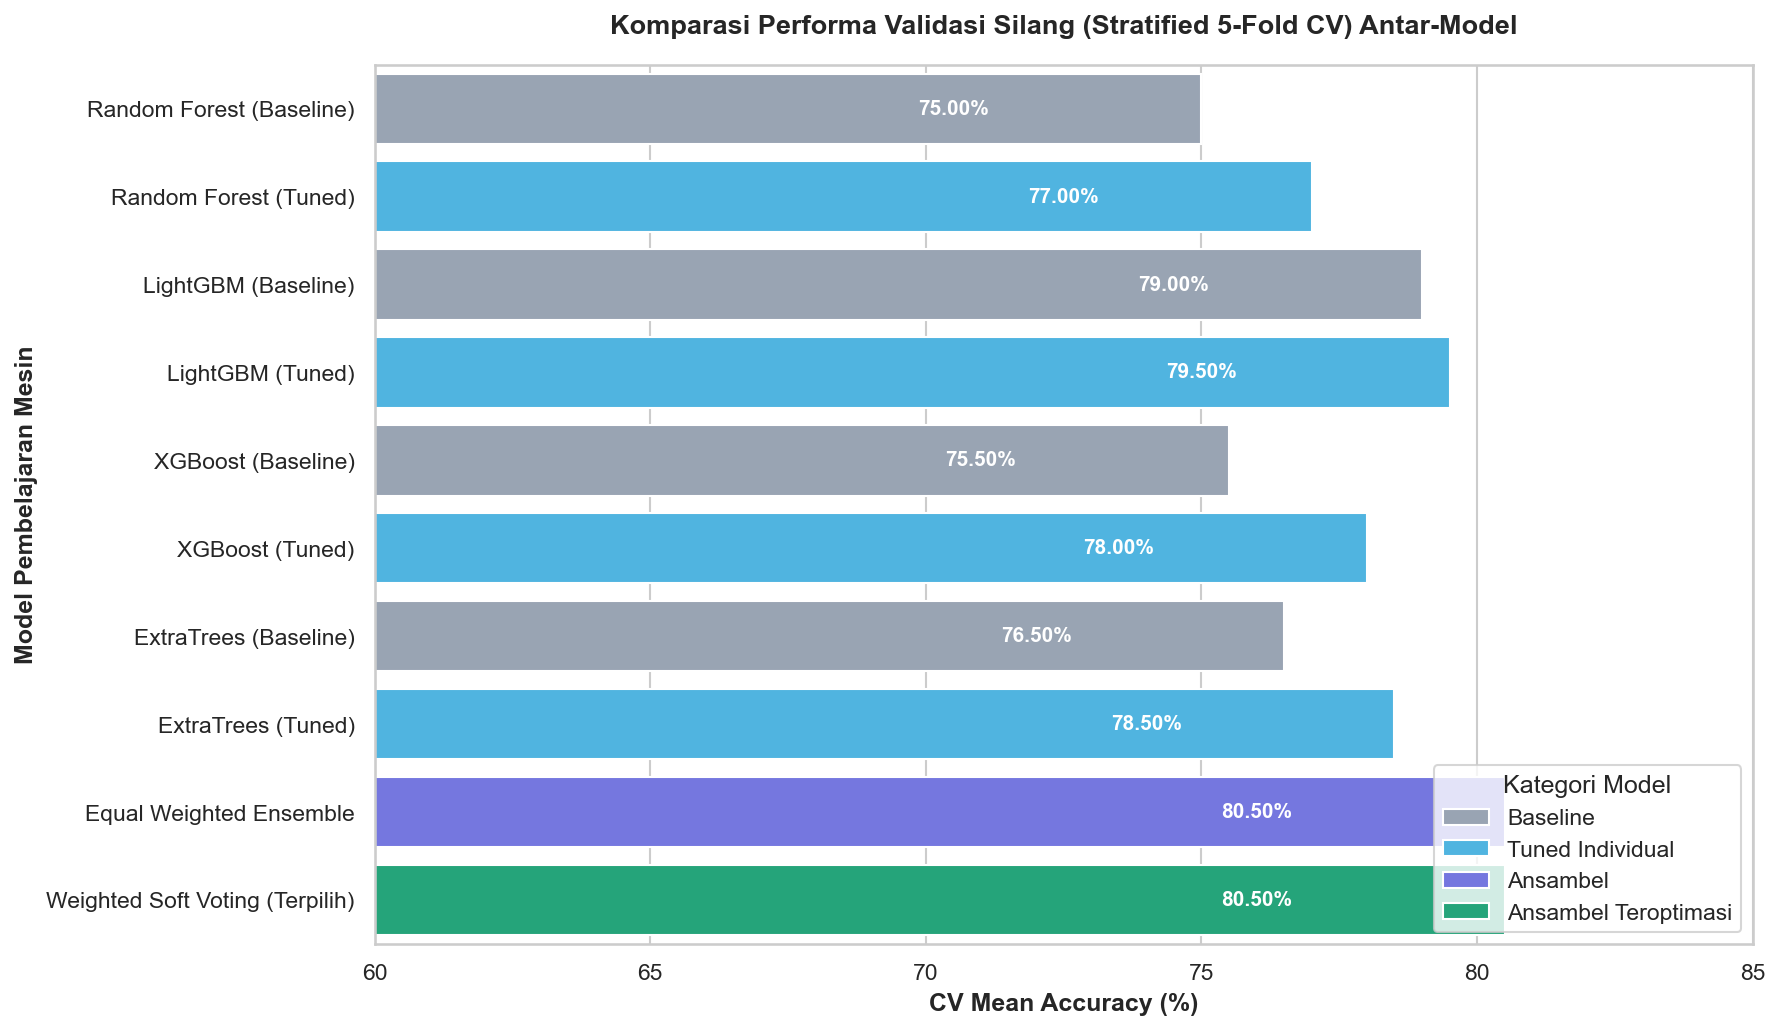

In [8]:
# Kompilasi Hasil Seluruh Model
comparison_data = [
    {'Model': 'Random Forest (Baseline)', 'Tipe': 'Baseline', 'CV Mean Accuracy (%)': scores_rf_base.mean()*100, 'Std Dev (%)': scores_rf_base.std()*100},
    {'Model': 'Random Forest (Tuned)', 'Tipe': 'Tuned Individual', 'CV Mean Accuracy (%)': scores_rf_tuned.mean()*100, 'Std Dev (%)': scores_rf_tuned.std()*100},
    {'Model': 'LightGBM (Baseline)', 'Tipe': 'Baseline', 'CV Mean Accuracy (%)': scores_lgb_base.mean()*100, 'Std Dev (%)': scores_lgb_base.std()*100},
    {'Model': 'LightGBM (Tuned)', 'Tipe': 'Tuned Individual', 'CV Mean Accuracy (%)': scores_lgb_tuned.mean()*100, 'Std Dev (%)': scores_lgb_tuned.std()*100},
    {'Model': 'XGBoost (Baseline)', 'Tipe': 'Baseline', 'CV Mean Accuracy (%)': scores_xgb_base.mean()*100, 'Std Dev (%)': scores_xgb_base.std()*100},
    {'Model': 'XGBoost (Tuned)', 'Tipe': 'Tuned Individual', 'CV Mean Accuracy (%)': scores_xgb_tuned.mean()*100, 'Std Dev (%)': scores_xgb_tuned.std()*100},
    {'Model': 'ExtraTrees (Baseline)', 'Tipe': 'Baseline', 'CV Mean Accuracy (%)': scores_et_base.mean()*100, 'Std Dev (%)': scores_et_base.std()*100},
    {'Model': 'ExtraTrees (Tuned)', 'Tipe': 'Tuned Individual', 'CV Mean Accuracy (%)': scores_et_tuned.mean()*100, 'Std Dev (%)': scores_et_tuned.std()*100},
    {'Model': 'Equal Weighted Ensemble', 'Tipe': 'Ansambel', 'CV Mean Accuracy (%)': scores_ens_equal.mean()*100, 'Std Dev (%)': scores_ens_equal.std()*100},
    {'Model': 'Weighted Soft Voting (Terpilih)', 'Tipe': 'Ansambel Teroptimasi', 'CV Mean Accuracy (%)': scores_model_terbaik.mean()*100, 'Std Dev (%)': scores_model_terbaik.std()*100}
]

comp_df = pd.DataFrame(comparison_data)

# Tampilan Format Tabel Ringkasan
display_df = comp_df.copy()
display_df['CV Mean Accuracy (%)'] = display_df['CV Mean Accuracy (%)'].map(lambda x: f"{x:.2f}%")
display_df['Std Dev (%)'] = display_df['Std Dev (%)'].map(lambda x: f"{x:.2f}%")
display(display_df)

# Visualisasi Grafik Batang Komparatif
plt.figure(figsize=(12, 7), dpi=150)
palette = {
    'Baseline': '#94a3b8',
    'Tuned Individual': '#38bdf8',
    'Ansambel': '#6366f1',
    'Ansambel Teroptimasi': '#10b981'
}

bars = sns.barplot(
    data=comp_df,
    y='Model',
    x='CV Mean Accuracy (%)',
    hue='Tipe',
    dodge=False,
    palette=palette
)

# Menambahkan Nilai Persentase pada Bar
for p in bars.patches:
    width = p.get_width()
    if not np.isnan(width) and width > 0:
        bars.annotate(
            f"{width:.2f}%",
            (width - 4.5, p.get_y() + p.get_height() / 2.),
            ha='center', va='center',
            color='white', fontweight='bold', fontsize=10
        )

plt.title('Komparasi Performa Validasi Silang (Stratified 5-Fold CV) Antar-Model', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('CV Mean Accuracy (%)', fontweight='bold')
plt.ylabel('Model Pembelajaran Mesin', fontweight='bold')
plt.xlim(60, 85)
plt.legend(title='Kategori Model', loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

## 4.5 Serialisasi Artefak Model Terlatih dan Penyimpanan Metadata

Seluruh model pembelajaran mesin yang telah dilatih disimpan ke direktori `models/` dalam format serialisasi biner `.pkl` menggunakan pustaka `joblib`. Selain itu, disimpan berkas `model_metadata.json` yang mencakup spesifikasi 29 fitur dan konfigurasi kelas untuk menjamin integritas dan reproduksibilitas pada tahap Evaluasi dan Deployment.

In [9]:
model_dir = 'models'
os.makedirs(model_dir, exist_ok=True)

# 1. Simpan Artefak Model
joblib.dump(model_terbaik, os.path.join(model_dir, 'model_terbaik.pkl'))
joblib.dump(rf_tuned, os.path.join(model_dir, 'best_random_forest.pkl'))
joblib.dump(lgb_tuned, os.path.join(model_dir, 'best_lightgbm.pkl'))
joblib.dump(xgb_tuned, os.path.join(model_dir, 'best_xgboost.pkl'))
joblib.dump(et_tuned, os.path.join(model_dir, 'best_extratrees.pkl'))
joblib.dump(ens_equal, os.path.join(model_dir, 'ensemble_equal_weight.pkl'))

# 2. Simpan Metadata Model
metadata = {
    'feature_cols': feature_cols,
    'total_features': len(feature_cols),
    'classes': ['Bangunan', 'Hutan', 'Hutan Mangrove', 'Perairan', 'Pertanian'],
    'n_classes': 5,
    'n_train': len(X_train),
    'cv_results': comp_df.to_dict(orient='records')
}

with open(os.path.join(model_dir, 'model_metadata.json'), 'w') as f:
    json.dump(metadata, f, indent=2)

print('[OK] Seluruh 6 artefak model (.pkl) dan metadata berhasil disimpan secara lengkap di folder models/.')

[OK] Seluruh 6 artefak model (.pkl) dan metadata berhasil disimpan secara lengkap di folder models/.
